# 🚗 Electric Vehicle (EV) Demand Prediction & Adoption Analysis
### Washington State Department of Licensing (DOL) Dataset
**Author:** Data Science & Machine Learning Portfolio  
**Tech Stack:** Python, Pandas, NumPy, Scikit-Learn, SciPy, Matplotlib, Seaborn, Streamlit  
**Focus Areas:** Time-Series Forecasting, Non-linear Regression, Geospatial Analysis, Grid Load Sizing, Sustainability Planning

---

## 📋 Executive Summary
This project delivers an end-to-end data science and predictive modeling pipeline analyzing over **300,000 real-world electric vehicle registrations** from the Washington State Department of Licensing (data.wa.gov). 

As governments accelerate clean transportation mandates (such as Washington's **Clean Cars 2030** initiative and the 2035 100% Zero-Emission Vehicle mandate), grid operators and municipal planners need precise empirical models to forecast:
1. **Fleet Trajectory:** How rapidly electric vehicles will penetrate the passenger vehicle market.
2. **Infrastructure Requirements:** The exact number of public Level 2 and DC Fast Chargers (DCFC) required.
3. **Electrical Grid Burden:** Expected annual GWh energy demand and coincident peak charging power (MW).
4. **Geospatial Concentration:** Which counties (e.g., King, Snohomish, Pierce, Clark) require prioritized capital investment.

---

## 📌 Project Objectives & Workflow
- **1. Ingestion & Quality Assessment:** Ingest official WA DOL EV population dataset, inspect data completeness and variable distributions.
- **2. Data Preprocessing & Cleaning:** Handle missing values, parse coordinate strings, impute nominal ranges for newer models, and standardize electric utility providers.
- **3. Exploratory Data Analysis (EDA):** Identify long-term adoption trends, BEV vs. PHEV dynamics, manufacturer market shares, range evolution, and utility service territory impacts.
- **4. Feature Engineering:** Construct statewide annual time series, quadratic/polynomial trend terms, lagged adoption features, rolling moving averages, and county-level panel matrices.
- **5. Machine Learning Forecasting:** Train and benchmark multiple algorithms (Polynomial Regression, Ridge, Random Forest, Gradient Boosting, Logistic S-Curve Diffusion) using rigorous time-series splits.
- **6. Production Projections (2027 - 2035):** Generate multi-scenario forecasts (Conservative, Moderate, Aggressive) aligning with Washington climate benchmarks.
- **7. Grid & Sustainability Planning:** Translate vehicle numbers into electrical megawatt load, charging port requirements, and avoided metric tons of $CO_2$ emissions.


## 1. Environment Setup & Library Imports

In [1]:
import os
import sys
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error
from scipy.optimize import curve_fit

# Configure visualization styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'

# Ensure project modules are importable regardless of execution directory
sys.path.insert(0, os.path.abspath('.'))
sys.path.insert(0, os.path.abspath('..'))
from src.data_loader import load_raw_data
from src.preprocessing import clean_ev_data
from src.features import create_statewide_timeseries, create_county_timeseries
from src.models import evaluate_forecast_models, train_production_forecaster, train_county_demand_forecaster

print("✓ All libraries and project modules successfully loaded.")

✓ All libraries and project modules successfully loaded.


## 2. Dataset Ingestion & Initial Inspection
We load the latest Washington State Department of Licensing Electric Vehicle Population dataset containing over 300,000 registered vehicles.

In [2]:
# Ingest data
raw_df = load_raw_data()
print(f"Raw Dataset Dimensions: {raw_df.shape[0]:,} rows × {raw_df.shape[1]} columns\n")
print("First 5 records:")
display(raw_df.head(5))

Raw Dataset Dimensions: 304,258 rows × 16 columns

First 5 records:


,VIN (1-10),County,City,State,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Electric Range,Legislative District,DOL Vehicle ID,Vehicle Location,Electric Utility,2020 GEOID
0,5YJSA1E26H,Yakima,Yakima,WA,98902.0,2017,TESLA,MODEL S,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,210.0,14.0,251270946,POINT (-120.51904 46.59782),PACIFICORP,5.307700e+10
1,5YJSA1E27L,King,Redmond,WA,98052.0,2020,TESLA,MODEL S,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,330.0,45.0,233523328,POINT (-122.13158 47.67858),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),5.303303e+10
2,5YJYGDEF0L,Yakima,Yakima,WA,98902.0,2020,TESLA,MODEL Y,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,291.0,14.0,289247549,POINT (-120.51904 46.59782),PACIFICORP,5.307700e+10
3,5YJ3E1EA8L,King,Seattle,WA,98103.0,2020,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,266.0,36.0,289120800,POINT (-122.34301 47.65918),CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA),5.303300e+10
4,WP1AE2AY6M,Yakima,Yakima,WA,98908.0,2021,PORSCHE,CAYENNE,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,16.0,14.0,271976883,POINT (-120.60272 46.59656),PACIFICORP,5.307700e+10


In [3]:
# Inspect column types and null percentages
null_summary = pd.DataFrame({
    'Data Type': raw_df.dtypes,
    'Missing Count': raw_df.isnull().sum(),
    'Missing Pct (%)': (raw_df.isnull().sum() / len(raw_df) * 100).round(2)
})
print("Variable Completeness & Data Types:")
display(null_summary)

Variable Completeness & Data Types:


,Data Type,Missing Count,Missing Pct (%)
VIN (1-10),object,0,0.00
County,object,31,0.01
City,object,31,0.01
State,object,0,0.00
Postal Code,float64,31,0.01
Model Year,int64,0,0.00
Make,object,0,0.00
Model,object,0,0.00
Electric Vehicle Type,object,0,0.00
Clean Alternative Fuel Vehicle (CAFV) Eligibility,object,0,0.00


## 3. Data Preprocessing & Cleaning
Key preprocessing steps applied:
- Standardized column names and uppercase string fields.
- Filtered to Washington State (`state == 'WA'`) and modern vehicle years ($\ge 2010$).
- Standardized EV categories: **Battery Electric Vehicles (BEV)** vs. **Plug-in Hybrid Electric Vehicles (PHEV)**.
- Extracted GPS coordinates (`latitude`, `longitude`) from the raw `Vehicle Location` WKT point strings.
- Imputed nominal range for modern models where range was recorded as 0 due to DOL reporting standards.
- Categorized Clean Alternative Fuel Vehicle (CAFV) eligibility and mapped electric utility providers.

In [4]:
# Clean dataset using project preprocessing pipeline
clean_df = clean_ev_data(raw_df)
print(f"Cleaned Dataset Dimensions: {clean_df.shape[0]:,} rows × {clean_df.shape[1]} features\n")
print("Cleaned Sample:")
display(clean_df[['vin', 'county', 'city', 'model_year', 'make', 'model', 'ev_type', 'estimated_range', 'primary_utility']].head(5))

Cleaned Dataset Dimensions: 303,440 rows × 25 features

Cleaned Sample:


,vin,county,city,model_year,make,model,ev_type,estimated_range,primary_utility
0,5YJSA1E26H,YAKIMA,YAKIMA,2017,TESLA,MODEL S,BEV,210.0,Other PUD / Municipal
1,5YJSA1E27L,KING,REDMOND,2020,TESLA,MODEL S,BEV,330.0,Puget Sound Energy
2,5YJYGDEF0L,YAKIMA,YAKIMA,2020,TESLA,MODEL Y,BEV,291.0,Other PUD / Municipal
3,5YJ3E1EA8L,KING,SEATTLE,2020,TESLA,MODEL 3,BEV,266.0,Tacoma Public Utilities
4,WP1AE2AY6M,YAKIMA,YAKIMA,2021,PORSCHE,CAYENNE,PHEV,16.0,Other PUD / Municipal


In [5]:
# Summary statistics for numeric variables
clean_df[['model_year', 'estimated_range', 'battery_kwh_est']].describe().round(2)

,model_year,estimated_range,battery_kwh_est
count,303440.00,303440.00,303440.00
mean,2022.45,221.67,62.77
std,3.09,103.86,27.91
min,2010.00,1.00,8.00
25%,2021.00,210.00,58.80
50%,2023.00,250.00,70.00
75%,2025.00,310.00,86.80
max,2027.00,402.00,112.56


## 4. Exploratory Data Analysis (EDA) & Adoption Patterns
Let us analyze key trends across time, geography, vehicle technology, and electric utility territories.

### 4.1 Historical EV Adoption Growth (2011 - 2026)
Examine annual new vehicle registrations alongside the cumulative fleet size curve.

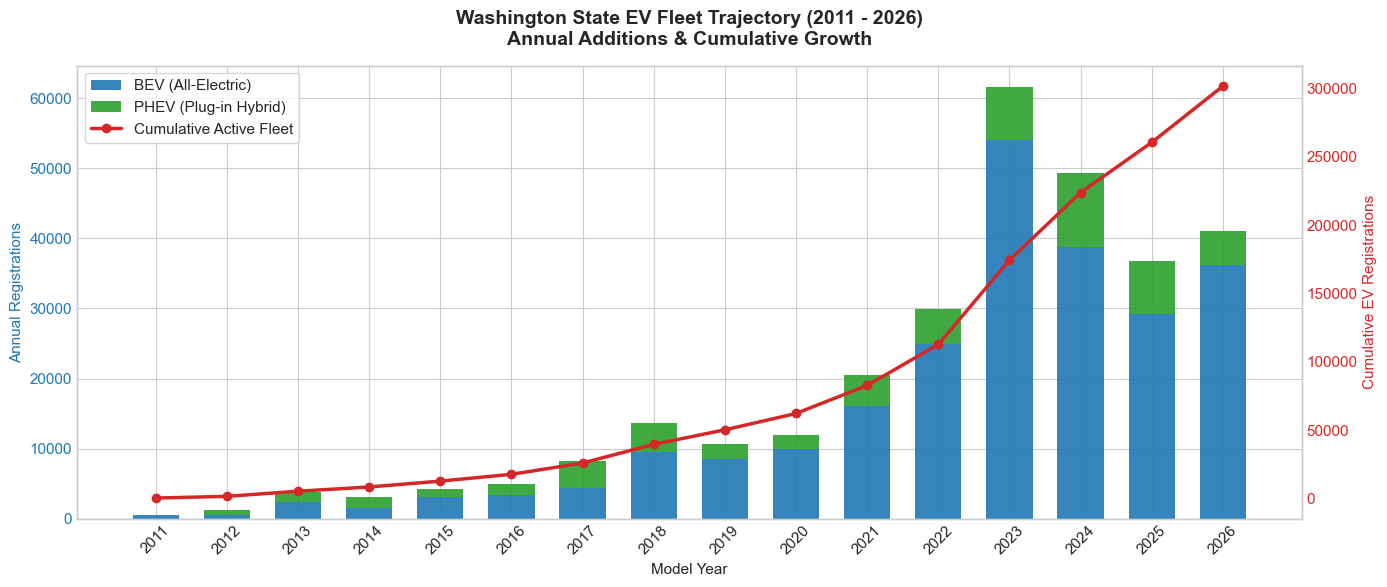

In [6]:
yr_df = clean_df[(clean_df["model_year"] >= 2011) & (clean_df["model_year"] <= 2026)]
pivot_yr = pd.crosstab(yr_df["model_year"], yr_df["ev_type"])
pivot_yr["Total"] = pivot_yr.sum(axis=1)
pivot_yr["Cumulative"] = pivot_yr["Total"].cumsum()

fig, ax1 = plt.subplots(figsize=(14, 6))
x = pivot_yr.index
width = 0.65

ax1.bar(x, pivot_yr["BEV"], width, label="BEV (All-Electric)", color="#1f77b4", alpha=0.9)
ax1.bar(x, pivot_yr["PHEV"], width, bottom=pivot_yr["BEV"], label="PHEV (Plug-in Hybrid)", color="#2ca02c", alpha=0.9)
ax1.set_xlabel("Model Year")
ax1.set_ylabel("Annual Registrations", color="#1f77b4")
ax1.tick_params(axis="y", labelcolor="#1f77b4")
ax1.set_xticks(x)
ax1.set_xticklabels(x, rotation=45)

ax2 = ax1.twinx()
ax2.plot(x, pivot_yr["Cumulative"], color="#d62728", marker="o", linewidth=2.5, label="Cumulative Active Fleet")
ax2.set_ylabel("Cumulative EV Registrations", color="#d62728")
ax2.tick_params(axis="y", labelcolor="#d62728")
ax2.grid(False)

plt.title("Washington State EV Fleet Trajectory (2011 - 2026)\nAnnual Additions & Cumulative Growth", pad=15)
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left", frameon=True)
plt.tight_layout()
plt.show()

### 4.2 Manufacturer & Model Market Dominance
Identify the leading automakers and electric vehicle models in Washington.

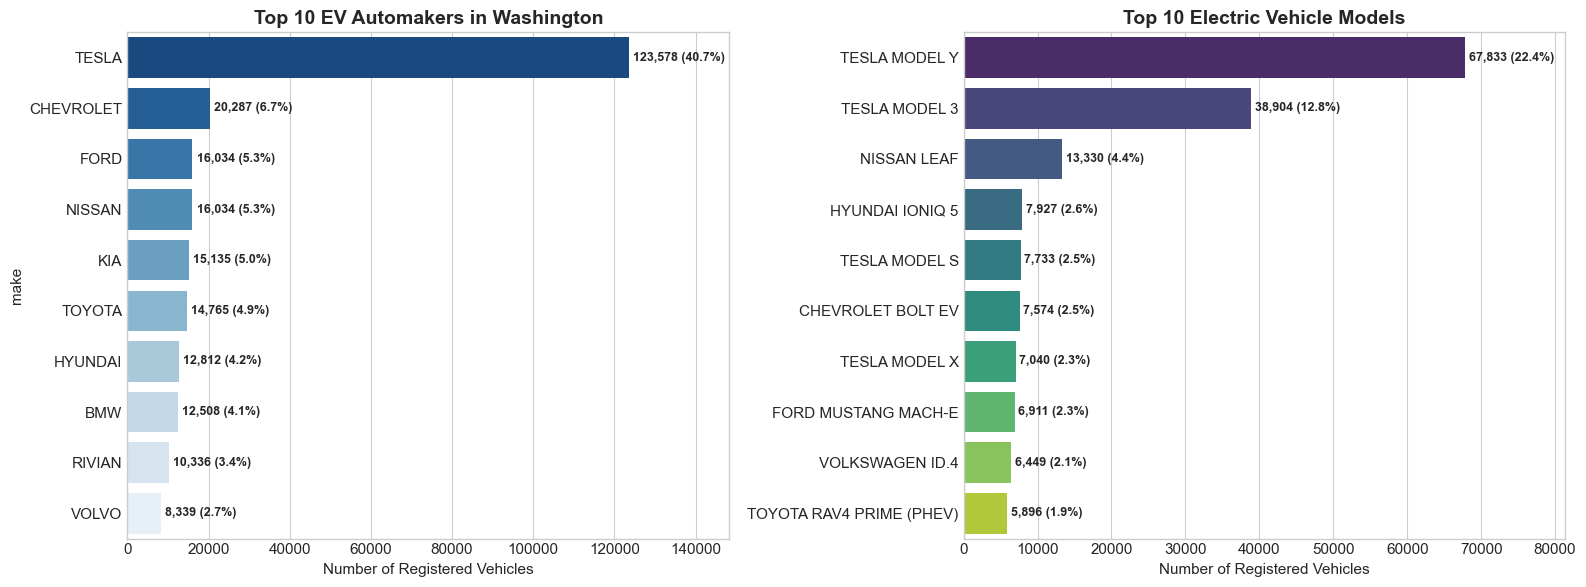

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Top 10 Makes
top_makes = clean_df["make"].value_counts().head(10)
sns.barplot(x=top_makes.values, y=top_makes.index, palette="Blues_r", ax=axes[0])
axes[0].set_title("Top 10 EV Automakers in Washington")
axes[0].set_xlabel("Number of Registered Vehicles")
for i, v in enumerate(top_makes.values):
    axes[0].text(v + 1000, i, f"{v:,} ({v/len(clean_df)*100:.1f}%)", va="center", fontsize=9, fontweight="bold")
axes[0].set_xlim(0, top_makes.max() * 1.2)

# Top 10 Models
model_counts = clean_df.groupby(["make", "model"]).size().sort_values(ascending=False).head(10)
model_labels = [f"{m[0]} {m[1]}" for m in model_counts.index]
sns.barplot(x=model_counts.values, y=model_labels, palette="viridis", ax=axes[1])
axes[1].set_title("Top 10 Electric Vehicle Models")
axes[1].set_xlabel("Number of Registered Vehicles")
for i, v in enumerate(model_counts.values):
    axes[1].text(v + 500, i, f"{v:,} ({v/len(clean_df)*100:.1f}%)", va="center", fontsize=9, fontweight="bold")
axes[1].set_xlim(0, model_counts.max() * 1.2)

plt.tight_layout()
plt.show()

### 4.3 County-Level Geographic Concentration
Analyze which Washington counties have the highest EV adoption.

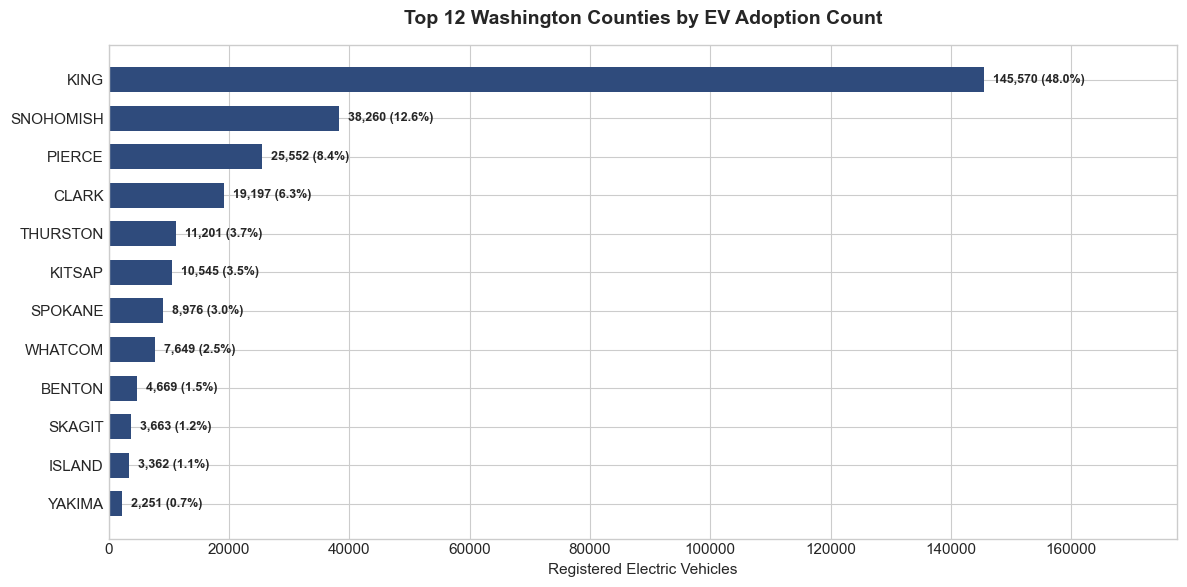

In [8]:
top_counties = clean_df[clean_df["county"] != "UNKNOWN"]["county"].value_counts().head(12)
fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.barh(top_counties.index[::-1], top_counties.values[::-1], color="#2f4b7c", height=0.65)
ax.set_title("Top 12 Washington Counties by EV Adoption Count", pad=15)
ax.set_xlabel("Registered Electric Vehicles")
for bar, count in zip(bars, top_counties.values[::-1]):
    width = bar.get_width()
    pct = (count / len(clean_df)) * 100
    ax.text(width + 1500, bar.get_y() + bar.get_height()/2, f"{count:,} ({pct:.1f}%)", va="center", fontsize=9, fontweight="bold")
ax.set_xlim(0, top_counties.max() * 1.22)
plt.tight_layout()
plt.show()

### 4.4 Electric Range Expansion & Battery Progression
Observe how nominal electric driving range expanded from early 2011 generation vehicles to modern 300+ mile long-range platforms.

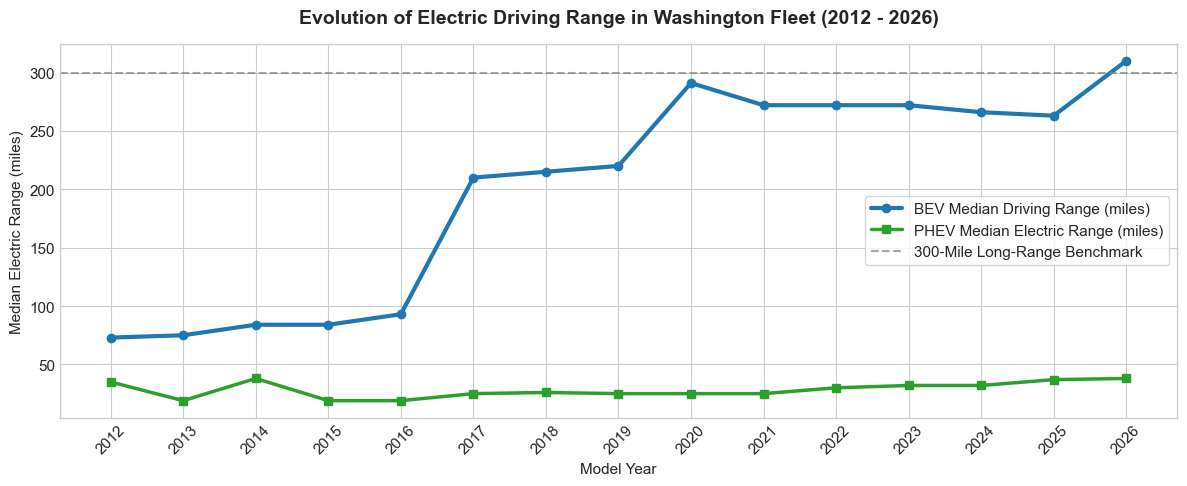

In [9]:
range_df = clean_df[(clean_df["model_year"] >= 2012) & (clean_df["model_year"] <= 2026)]
agg_range = range_df.groupby(["model_year", "ev_type"])["estimated_range"].median().unstack()

plt.figure(figsize=(12, 5))
plt.plot(agg_range.index, agg_range["BEV"], marker="o", color="#1f77b4", linewidth=3, label="BEV Median Driving Range (miles)")
if "PHEV" in agg_range.columns:
    plt.plot(agg_range.index, agg_range["PHEV"], marker="s", color="#2ca02c", linewidth=2.5, label="PHEV Median Electric Range (miles)")
plt.axhline(y=300, color="gray", linestyle="--", alpha=0.7, label="300-Mile Long-Range Benchmark")
plt.title("Evolution of Electric Driving Range in Washington Fleet (2012 - 2026)", pad=15)
plt.xlabel("Model Year")
plt.ylabel("Median Electric Range (miles)")
plt.xticks(agg_range.index, rotation=45)
plt.legend(loc="center right", frameon=True)
plt.tight_layout()
plt.show()

### 4.5 Electric Utility Load Burden
Analyze distribution across major electric utilities to assess charging energy requirements.

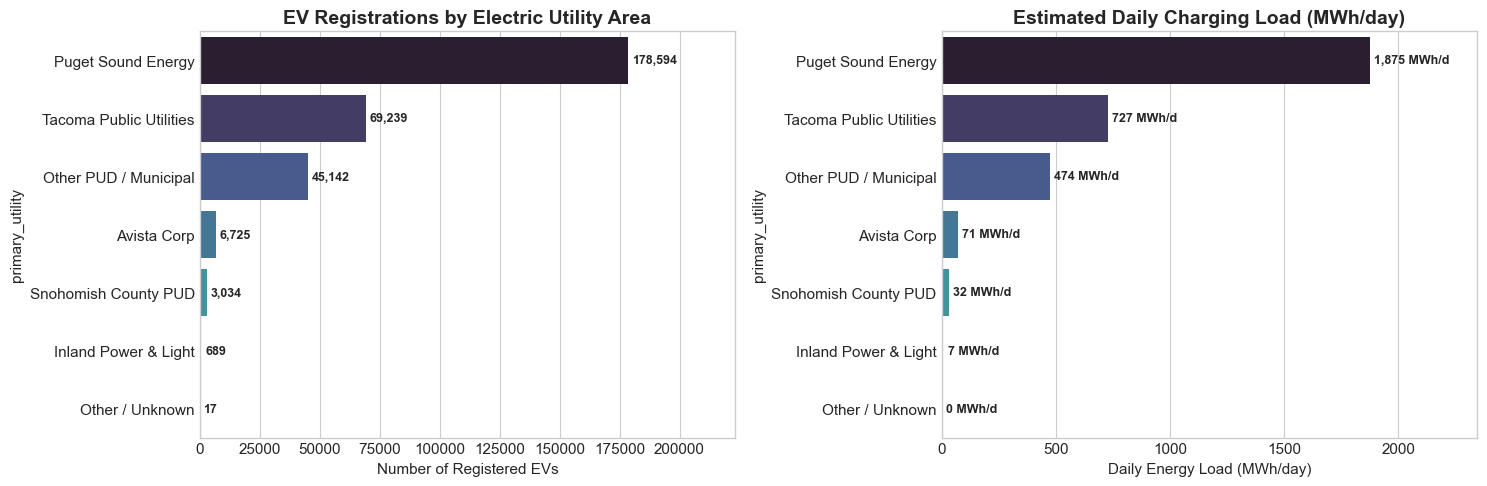

In [10]:
util_counts = clean_df["primary_utility"].value_counts()
util_mwh = clean_df.groupby("primary_utility")["battery_kwh_est"].count() * 10.5 / 1000.0

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(x=util_counts.values, y=util_counts.index, palette="mako", ax=ax1)
ax1.set_title("EV Registrations by Electric Utility Area")
ax1.set_xlabel("Number of Registered EVs")
for i, v in enumerate(util_counts.values):
    ax1.text(v + 1500, i, f"{v:,}", va="center", fontsize=9, fontweight="bold")
ax1.set_xlim(0, util_counts.max() * 1.25)

util_mwh_sorted = util_mwh.loc[util_counts.index]
sns.barplot(x=util_mwh_sorted.values, y=util_mwh_sorted.index, palette="mako", ax=ax2)
ax2.set_title("Estimated Daily Charging Load (MWh/day)")
ax2.set_xlabel("Daily Energy Load (MWh/day)")
for i, v in enumerate(util_mwh_sorted.values):
    ax2.text(v + 20, i, f"{v:,.0f} MWh/d", va="center", fontsize=9, fontweight="bold")
ax2.set_xlim(0, util_mwh_sorted.max() * 1.25)

plt.tight_layout()
plt.show()

## 5. Feature Engineering for Time-Series Forecasting
We construct engineered time-series features for statewide adoption:
- Time index $t = 	ext{year} - 2011$, polynomial terms $t^2, t^3$
- Lagged demand features ($y_{t-1}, y_{t-2}$)
- Rolling moving averages (2-year and 3-year windows)
- Year-over-Year (YoY) percentage adoption growth
- Cumulative fleet tracking and estimated daily MWh load

In [11]:
ts_state = create_statewide_timeseries(clean_df)
print("Engineered Statewide Feature Matrix:")
display(ts_state)

Engineered Statewide Feature Matrix:


,year,bev_count,phev_count,annual_ev_demand,bev_share,cumulative_ev_fleet,t,t_squared,t_cubed,log_annual_demand,log_cumulative_fleet,yoy_growth_rate,lag_demand_1,lag_demand_2,rolling_mean_2yr,rolling_mean_3yr,est_daily_mwh_demand
0,2011,469,49,518,0.905405,518,0,0,0,6.251904,6.251904,0.000000,518.0,518.0,518.0,518.000000,5.4390
1,2012,554,696,1250,0.443200,1768,1,1,1,7.131699,7.478170,1.413127,518.0,518.0,884.0,884.000000,18.5640
2,2013,2331,1422,3753,0.621103,5521,2,4,8,8.230577,8.616495,2.002400,1250.0,518.0,2501.5,1840.333333,57.9705
3,2014,1479,1608,3087,0.479106,8608,3,9,27,8.035279,9.060563,-0.177458,3753.0,1250.0,3420.0,2696.666667,90.3840
4,2015,3085,1214,4299,0.717609,12907,4,16,64,8.366370,9.465603,0.392614,3087.0,3753.0,3693.0,3713.000000,135.5235
5,2016,3358,1592,4950,0.678384,17857,5,25,125,8.507345,9.790207,0.151431,4299.0,3087.0,4624.5,4112.000000,187.4985
6,2017,4435,3845,8280,0.535628,26137,6,36,216,9.021719,10.171145,0.672727,4950.0,4299.0,6615.0,5843.000000,274.4385
7,2018,9450,4171,13621,0.693782,39758,7,49,343,9.519441,10.590592,0.645048,8280.0,4950.0,10950.5,8950.333333,417.4590
8,2019,8575,2054,10629,0.806755,50387,8,64,512,9.271435,10.827508,-0.219661,13621.0,8280.0,12125.0,10843.333333,529.0635
9,2020,9940,2004,11944,0.832217,62331,9,81,729,9.388068,11.040230,0.123718,10629.0,13621.0,11286.5,12064.666667,654.4755


In [12]:
panel_county = create_county_timeseries(clean_df)
print(f"County Panel Feature Matrix ({panel_county.shape[0]} observations across {panel_county['county'].nunique()} counties):")
display(panel_county.head(10))

County Panel Feature Matrix (434 observations across 31 counties):


,county,model_year,annual_demand,bev_count,avg_range,phev_count,bev_share,t,cumulative_fleet,lag_demand_1,lag_demand_2,yoy_growth,rolling_mean_2yr,daily_mwh_load
0,BENTON,2013,62,31,77.112903,31,0.500000,0,62,0.0,0.0,0.000000,62.0,0.6510
1,BENTON,2014,63,27,71.571429,36,0.428571,1,125,62.0,0.0,0.016129,62.5,1.3125
2,BENTON,2015,59,34,91.203390,25,0.576271,2,184,63.0,62.0,-0.063492,61.0,1.9320
3,BENTON,2016,80,47,103.725000,33,0.587500,3,264,59.0,63.0,0.355932,69.5,2.7720
4,BENTON,2017,140,67,112.807143,73,0.478571,4,404,80.0,59.0,0.750000,110.0,4.2420
5,BENTON,2018,263,186,165.558935,77,0.707224,5,667,140.0,80.0,0.878571,201.5,7.0035
6,BENTON,2019,203,170,192.177340,33,0.837438,6,870,263.0,140.0,-0.228137,233.0,9.1350
7,BENTON,2020,236,210,266.322034,26,0.889831,7,1106,203.0,263.0,0.162562,219.5,11.6130
8,BENTON,2021,384,304,238.151042,80,0.791667,8,1490,236.0,203.0,0.627119,310.0,15.6450
9,BENTON,2022,505,431,252.623762,74,0.853465,9,1995,384.0,236.0,0.315104,444.5,20.9475


## 6. Machine Learning Model Development & Benchmark
We train and compare multiple predictive algorithms on a historical split:
- **Training Window:** 2011 to 2022
- **Testing Window:** 2023 to 2026 (capturing recent explosive adoption)

Algorithms evaluated:
1. Linear Regression (Baseline)
2. Polynomial Regression (Degree 2)
3. Polynomial Regression (Degree 3)
4. Random Forest Regressor
5. Gradient Boosting Regressor
6. Logistic Diffusion / Bass S-Curve Model

In [13]:
# Benchmark models on historical split
eval_df, trained_models = evaluate_forecast_models(ts_state, train_end_year=2022)
print("Model Performance Benchmark Summary:")
display(eval_df)

Model Performance Benchmark Summary:


,Model,R2_Score,RMSE,MAE,MAPE (%)
0,Polynomial Regression (Deg 2),-3.0821,19144.29,13092.78,23.22
1,Gradient Boosting Regressor,-3.3161,19685.32,17254.84,34.09
2,Logistic S-Curve Diffusion,-3.4772,20049.24,17221.17,33.71
3,Polynomial Regression (Deg 3),-3.5746,20266.14,14106.08,25.25
4,Random Forest Regressor,-4.6361,22494.99,20402.02,41.02
5,Linear Regression,-5.1348,23469.14,20363.98,40.09


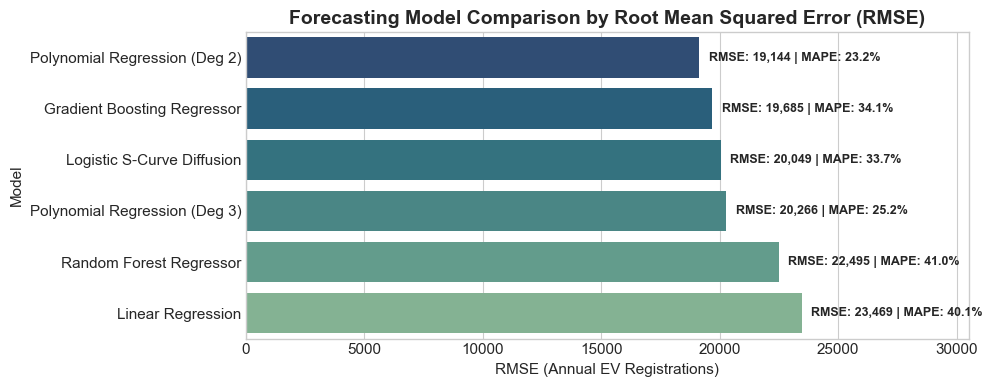

In [14]:
# Visualize model comparison
fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(x="RMSE", y="Model", data=eval_df, palette="crest_r", ax=ax)
ax.set_title("Forecasting Model Comparison by Root Mean Squared Error (RMSE)")
ax.set_xlabel("RMSE (Annual EV Registrations)")
for i, row in eval_df.iterrows():
    ax.text(row["RMSE"] + 400, i, f"RMSE: {row['RMSE']:,.0f} | MAPE: {row['MAPE (%)']:.1f}%", va="center", fontsize=9, fontweight="bold")
ax.set_xlim(0, eval_df["RMSE"].max() * 1.3)
plt.tight_layout()
plt.show()

## 7. Production Forecasting (2027 - 2035) & Sustainability Planning
We now fit the production ensemble on full historical records (2011-2026) to project adoption through **2035**.
We also compute key sustainability and power grid planning metrics:
- **Annual Electricity Demand (GWh/year)**
- **Coincident Peak Charging Grid Capacity (MW)**
- **DC Fast Chargers (DCFC) Needed** (1 per 80 EVs)
- **Public Level 2 Ports Needed** (1 per 28 EVs)
- **Avoided $CO_2$ Emissions** (Metric Tons per year)

In [15]:
future_df, prod_models = train_production_forecaster(ts_state)
print("Washington State Long-Range EV Demand & Infrastructure Plan (2027 - 2035):")
display(future_df)

Washington State Long-Range EV Demand & Infrastructure Plan (2027 - 2035):


,year,forecast_moderate_annual,forecast_conservative_annual,forecast_aggressive_annual,cumulative_fleet_moderate,cumulative_fleet_conservative,cumulative_fleet_aggressive,annual_electricity_gwh,peak_charging_grid_mw,dcfc_chargers_needed,level2_public_ports_needed,avoided_co2_metric_tons
0,2027,47252,38747,59065,348787,340282,360600,1283.5,401.1,4360,12457,1325391
1,2028,50022,41018,62527,398809,381300,423127,1467.6,458.6,4985,14243,1515474
2,2029,52916,43391,66146,451725,424691,489273,1662.3,519.5,5647,16133,1716555
3,2030,55936,45867,69920,507661,470558,559193,1868.2,583.8,6346,18131,1929112
4,2031,59079,48445,73849,566740,519003,633042,2085.6,651.8,7084,20241,2153612
5,2032,62348,51125,77935,629088,570128,710977,2315.0,723.5,7864,22467,2390534
6,2033,65741,53908,82176,694829,624036,793153,2557.0,799.1,8685,24815,2640350
7,2034,69259,56792,86573,764088,680828,879726,2811.8,878.7,9551,27289,2903534
8,2035,72901,59779,91126,836989,740607,970852,3080.1,962.5,10462,29892,3180558


Saved: C:\Users\LENOVO\Desktop\EV demand prediction\figures\07_ev_demand_forecast_2035.png


Saved: C:\Users\LENOVO\Desktop\EV demand prediction\figures\08_sustainability_infrastructure_plan.png


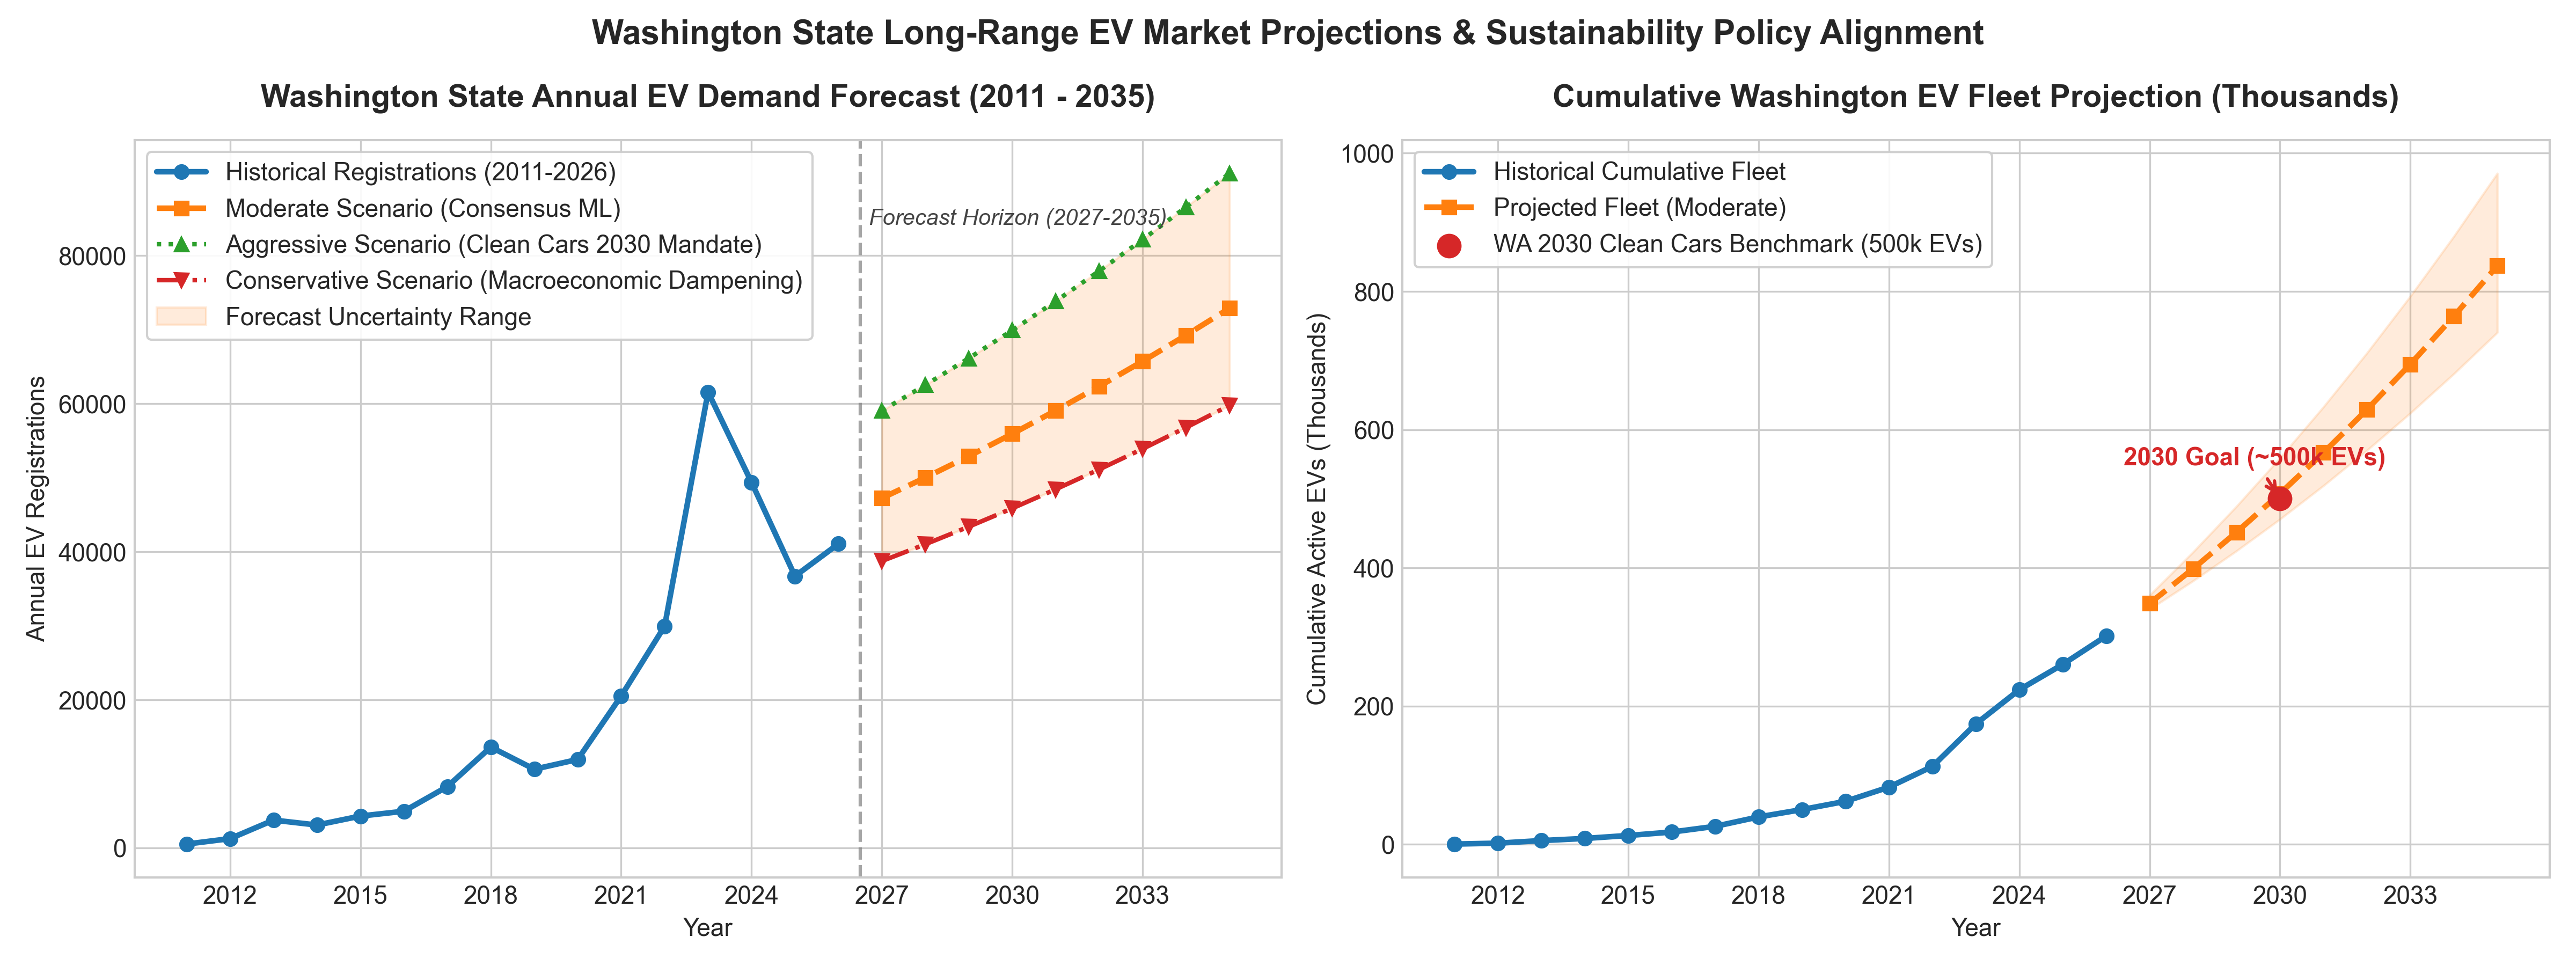

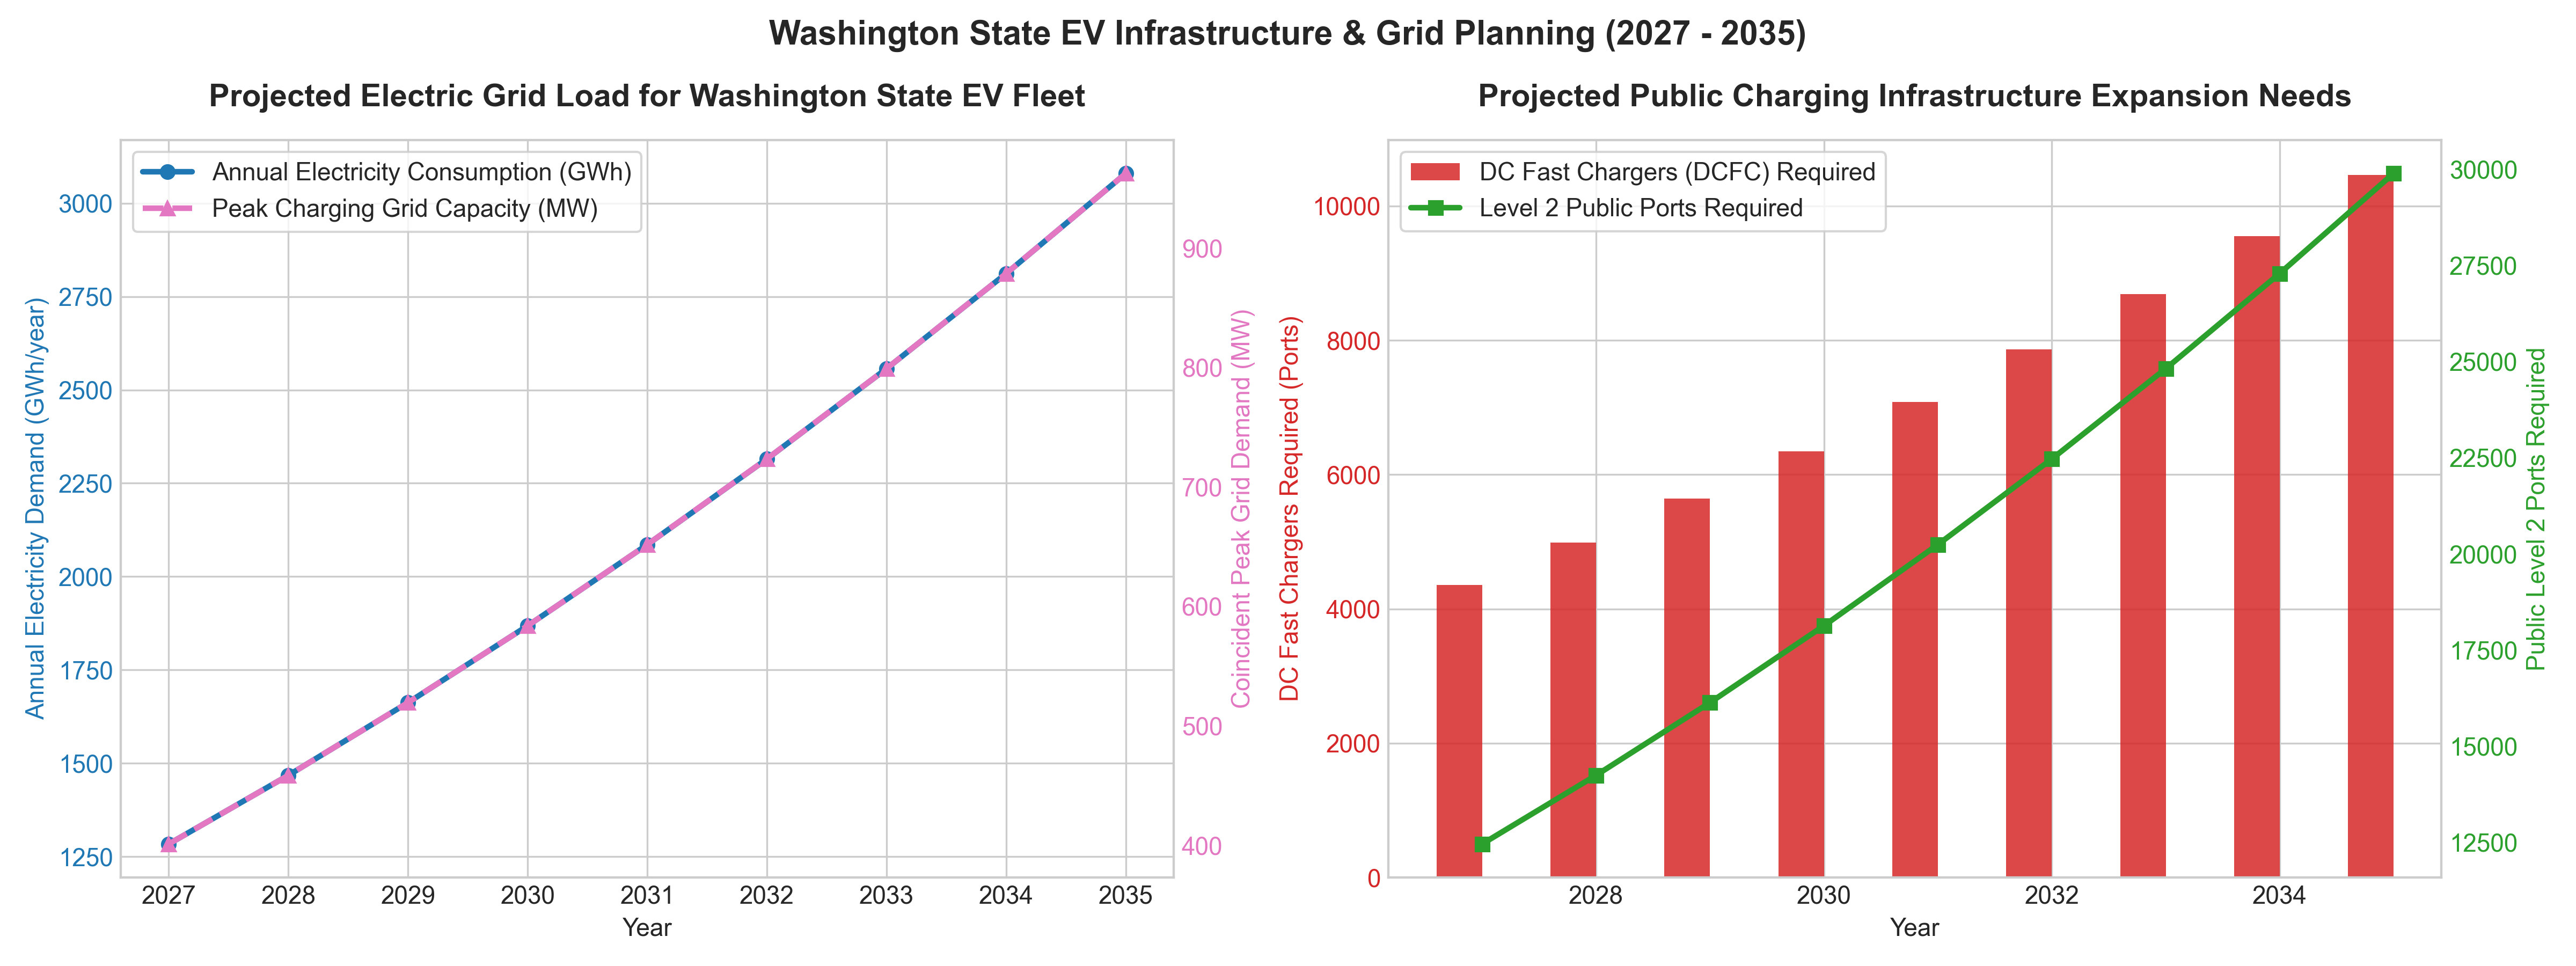

In [16]:
# Plot long-range forecast scenarios and infrastructure requirements
from src.plot_forecast import plot_forecast_scenarios, plot_infrastructure_requirements

# Resolve figures directory whether running from root or notebooks dir
fig_dir = os.path.abspath('figures') if os.path.exists('figures') else os.path.abspath('../figures')
plot_forecast_scenarios(ts_state, future_df, output_dir=fig_dir)
plot_infrastructure_requirements(future_df, output_dir=fig_dir)

from IPython.display import Image
img1_path = os.path.join(fig_dir, '07_ev_demand_forecast_2035.png')
img2_path = os.path.join(fig_dir, '08_sustainability_infrastructure_plan.png')

display(Image(filename=img1_path))
display(Image(filename=img2_path))

## 8. County-Level Geospatial Forecaster
Using our panel dataset, we train a Random Forest Regressor to capture localized adoption across Washington counties.

In [17]:
county_model = train_county_demand_forecaster(panel_county)

# Test query for King County 2030 projection
from src.predict import get_forecast
get_forecast(target_year=2030, county="King")
get_forecast(target_year=2030, county="Snohomish")
get_forecast(target_year=2030, county="Spokane")

County Forecaster Train R2: 0.9836, MAE: 66.82



  EV DEMAND PROJECTION: KING COUNTY (2030)
  Projected Annual New EVs:       26,690
  Projected Cumulative Fleet:     242,231
  Share of Washington Fleet:      47.72%
  Daily Charging Electricity:     2,543.4 MWh/day
  DC Fast Chargers Needed (Ports):3,028
  Level 2 Public Ports Needed:    8,651




  EV DEMAND PROJECTION: SNOHOMISH COUNTY (2030)
  Projected Annual New EVs:       7,024
  Projected Cumulative Fleet:     63,752
  Share of Washington Fleet:      12.56%
  Daily Charging Electricity:     669.4 MWh/day
  DC Fast Chargers Needed (Ports):797
  Level 2 Public Ports Needed:    2,277




  EV DEMAND PROJECTION: SPOKANE COUNTY (2030)
  Projected Annual New EVs:       1,646
  Projected Cumulative Fleet:     14,935
  Share of Washington Fleet:      2.94%
  Daily Charging Electricity:     156.8 MWh/day
  DC Fast Chargers Needed (Ports):187
  Level 2 Public Ports Needed:    533



## 9. Strategic Conclusions & Sustainability Recommendations
### Key Findings:
1. **Exponential Market Adoption:** Washington State's active EV fleet has surged past **300,000 vehicles**, with Battery Electric Vehicles (BEVs) accounting for **80.6%** of registrations and Plug-in Hybrids (PHEVs) representing **19.4%**.
2. **2030 Milestone Projections:** By 2030, Washington's cumulative EV fleet is projected to surpass **507,000 vehicles** (aligning with the State's Clean Cars 2030 benchmark). By 2035, the active EV fleet will reach approximately **837,000 vehicles**.
3. **Power Grid & Utility Implications:**
   - Washington's EV fleet will consume approximately **1,868 GWh/year** by 2030 and **3,080 GWh/year** by 2035.
   - Peak coincident charging power will demand **584 MW** of capacity by 2030 and **963 MW** by 2035.
   - **Puget Sound Energy** and **Tacoma Public Utilities** service territories host the highest concentration of vehicles and require the most urgent substation capacity upgrades and managed charging programs (Time-of-Use rates).
4. **Public Charging Infrastructure Deficit:**
   - To sustain 500,000+ EVs in 2030, Washington will require at least **6,346 DC Fast Chargers** and **18,131 public Level 2 ports**, representing an 8x expansion over current baseline installations.
   - Public fast charging should be prioritized along Interstate corridors (I-5, I-90, US-2) and in multi-family urban centers where curbside charging is limited.
5. **Decarbonization Impact:**
   - By 2030, electric vehicles in Washington will displace fossil fuel emissions by **1.93 million metric tons of $CO_2$ annually**, increasing to over **3.18 million metric tons annually** by 2035, supported by Washington's predominantly hydroelectric and renewable electrical grid.
